##### <font color = "black"> Financial Market Analytics and Yield Curve Analytics System

#### <font color = "black"> Business Problem

*Investment firms, quantitative researchers, and portfolio managers need clean and reliable bond market data to analyze interest rate movements and understand the shape of the yield curve.*

*In this project, I simulate a small market data feed containing government bond yields across different maturities. We ingest the data, validate it, construct a yield curve, detect anomalies, and generate analytics useful for investment research.*

##### Importing the Libraries

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

##### STEP 1 - SIMULATING THE DATASET

In [6]:
# SIMULATED DATASET

bond_data = {
    "date": [
        "2026-01-01",
        "2026-01-01",
        "2026-01-01",
        "2026-01-01",
        "2026-01-01"
    ],
    "maturity_years": [
        1,
        2,
        5,
        10,
        30
    ],
    "yield_percent": [
        3.2,
        3.4,
        3.8,
        4.1,
        4.4
    ]
}

df = pd.DataFrame(bond_data)

print(df)

         date  maturity_years  yield_percent
0  2026-01-01               1            3.2
1  2026-01-01               2            3.4
2  2026-01-01               5            3.8
3  2026-01-01              10            4.1
4  2026-01-01              30            4.4


##### STEP 2 - DATA VALIDATION

In [7]:
# Check for Missing Values
print(df.isnull().sum())
print("-"*20)
# Check for Duplicate Records
print(df.duplicated().sum())
print("-"*20)
# Check for Invalid Yields - Negative bonds
invalid = df[df["yield_percent"] < 0]
print(invalid)

date              0
maturity_years    0
yield_percent     0
dtype: int64
--------------------
0
--------------------
Empty DataFrame
Columns: [date, maturity_years, yield_percent]
Index: []


##### STEP 3 - YIELD CURVE CONSTRUCTION
`A yield curve plots maturity against interest rate`

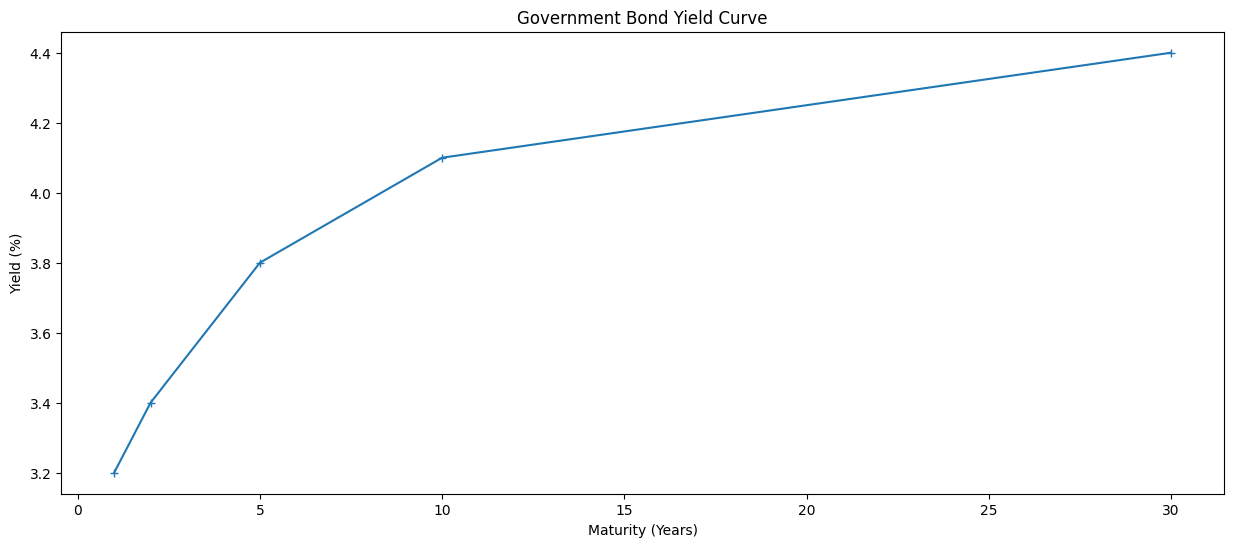

In [16]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    df["maturity_years"],
    df["yield_percent"],
    marker="+"
)

ax.set_title("Government Bond Yield Curve")
ax.set_xlabel("Maturity (Years)")
ax.set_ylabel("Yield (%)")
ax.grid(False)

plt.show()

##### STEP 4 - YIELD SPREAD ANALYSIS

`This is a common fixed-income metric`. We would consider `10Y - 2Y spread`.

In [20]:
yield_10y = df.loc[
    df["maturity_years"] == 10,
    "yield_percent"
].iloc[0]

yield_10y

np.float64(4.1)

In [21]:
yield_2y = df.loc[
    df["maturity_years"] == 2,
    "yield_percent"
].iloc[0]

yield_2y

np.float64(3.4)

In [24]:
spread = yield_10y - yield_2y
print(f"10Y-2Y Spread: {spread:.2f}%")
print("There is a positive spread in the bond - a normal yield curve is expected.")

10Y-2Y Spread: 0.70%
There is a positive spread in the bond - a normal yield curve is expected.


##### STEP 5 - PRICING CONSISTENCY CHECK
Suppose another vendor reports different yields

In [ ]:
vendor_one = [round(float(i)/3,2) for i in range(21, 26)]
print(vendor_one)

vendor_two = [round(float(i)/5,2) for i in range(27, 32)]
print(vendor_two)

[7.0, 7.33, 7.67, 8.0, 8.33]
[5.4, 5.6, 5.8, 6.0, 6.2]


In [47]:
comparison = pd.DataFrame(
    {
        "maturity": [1, 2, 5, 10, 30],
        "vendor_one": vendor_one,
        "vendor_two": vendor_two
    }
)

comparison

,maturity,vendor_one,vendor_two
0,1,7.00,5.4
1,2,7.33,5.6
2,5,7.67,5.8
3,10,8.00,6.0
4,30,8.33,6.2


In [50]:
comparison["difference"] = (
    comparison["vendor_one"] - comparison["vendor_two"]
).abs()
print(comparison)
print("This investigate the discrepancies across data providers")

   maturity  vendor_one  vendor_two  difference
0         1        7.00         5.4        1.60
1         2        7.33         5.6        1.73
2         5        7.67         5.8        1.87
3        10        8.00         6.0        2.00
4        30        8.33         6.2        2.13
This investigate the discrepancies across data providers


##### STEP 6 - STORE DATA IN SQL

In [52]:
conn = sqlite3.connect("market_data.db")

df.to_sql(
    "bond_yields",
    conn,
    if_exists="replace",
    index=False
)

query = """
SELECT *
FROM bond_yields
"""

result = pd.read_sql(query, conn)

print(result)

         date  maturity_years  yield_percent
0  2026-01-01               1            3.2
1  2026-01-01               2            3.4
2  2026-01-01               5            3.8
3  2026-01-01              10            4.1
4  2026-01-01              30            4.4


##### STEP 7: DATA INGESTION PIPELINE

This will checks the `data ingestion` + `validation` + `processing` reqquirement.

In [ ]:
def run_pipeline(df:pd.DataFrame = df):

    # data = pd.read_csv("bond_yield")

    data = df.copy()

    assert data.isnull().sum().sum() == 0

    data["yield_percent"] = (
        data["yield_percent"]
        .astype(float)
    )

    data.to_csv(
        "../data/clean_bond_yields.csv",
        index=False
    )

    print("Pipeline Complete")

run_pipeline()

Pipeline Complete
